# Neural Network SMS Text Classifier

**Author: cear12**

A solution to the [freeCodeCamp project](https://www.freecodecamp.org/learn/machine-learning-with-python/machine-learning-with-python-projects/neural-network-sms-text-classifier).
Classify SMS messages as **ham** (ordinary messages) or **spam** (unsolicited messages).
`predict_message(text)` returns `[spam_score, label]`, with a Python float between
zero and one and a label of `ham` or `spam`.

Run all cells in Google Colab or Jupyter. The notebook is self-contained and downloads
the original datasets. It learns from text features using a Keras neural network;
the official test messages are used only in the unchanged final acceptance check.

In [1]:
import os
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import csv
import hashlib
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 42
tf.config.threading.set_intra_op_parallelism_threads(min(4, os.cpu_count() or 1))
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
CACHE = Path(".cache")
ARTIFACTS = Path("artifacts")
CACHE.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)
print(f"TensorFlow {tf.__version__}; seed {SEED}")

TensorFlow 2.20.0; seed 42


## 1. Load and verify the official data

The supplied training and test files are tab-separated, with no header. Their SHA-256
checksums are checked before use. The original freeCodeCamp CDN has an official GitHub
mirror as a fallback. Labels are encoded as **ham = 0**, **spam = 1**.

In [2]:
DATA_HASHES = {
    "train-data.tsv": "7a72d271d37f9ee79e620df72731727abc9d950702a758525b5503a890c4d6d2",
    "valid-data.tsv": "803f7f5908845838de3a42811256779b1eed026e94cde7a65fcaa94c8f260b8d",
}


def prepare_file(name, cache=CACHE):
    if name not in DATA_HASHES:
        raise ValueError("Unknown dataset filename")
    target = Path(cache) / name
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists() and hashlib.sha256(target.read_bytes()).hexdigest() == DATA_HASHES[name]:
        return target
    urls = ("https://cdn.freecodecamp.org/project-data/sms/" + name,
            "https://raw.githubusercontent.com/freeCodeCamp/cdn/main/build/project-data/sms/" + name)
    errors = []
    for url in urls:
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request, timeout=60) as response:
                content = response.read()
            if hashlib.sha256(content).hexdigest() != DATA_HASHES[name]:
                raise ValueError("Dataset checksum mismatch")
            target.write_bytes(content)
            return target
        except (OSError, ValueError) as error:
            errors.append(f"{url}: {error}")
    raise RuntimeError("Dataset download failed:\n" + "\n".join(errors))


def read_messages(path):
    frame = pd.read_csv(path, sep="\t", header=None, names=["label", "message"],
                        dtype=str, quoting=csv.QUOTE_NONE, keep_default_na=False)
    if frame.empty or not frame["label"].isin(["ham", "spam"]).all():
        raise ValueError("Each SMS must have a ham or spam label")
    if frame["message"].str.strip().eq("").any():
        raise ValueError("SMS texts must not be empty")
    frame["target"] = frame["label"].map({"ham": 0, "spam": 1}).astype(np.float32)
    return frame

In [3]:
train_file_path = prepare_file("train-data.tsv")
test_file_path = prepare_file("valid-data.tsv")
raw_training = read_messages(train_file_path)
test_messages = read_messages(test_file_path)
print(f"Provided training rows: {len(raw_training):,}; provided test rows: {len(test_messages):,}")
print("Training label counts:", raw_training["label"].value_counts().to_dict())

Provided training rows: 4,179; provided test rows: 1,392
Training label counts: {'ham': 3619, 'spam': 560}


## 2. Remove training duplicates and reserve validation messages

Remove identical training texts before a stratified 80% / 20% fitting/validation split.
Conflicting labels for the same text are rejected. This prevents identical SMS texts
from appearing in both fitting and validation subsets.

The supplied test file contains some exact texts also present in the supplied training
file. Report its official metrics and separately evaluate unique test texts absent from
the entire training pool. The test file is not used for vocabulary, fitting, class weights,
early stopping, checkpoint selection or threshold selection.

In [4]:
def split_training(frame, seed=42):
    if (frame.groupby("message")["label"].nunique() > 1).any():
        raise ValueError("Identical training texts have conflicting labels")
    unique = frame.drop_duplicates("message").copy()
    fitting, validation = train_test_split(
        unique, test_size=0.2, random_state=seed, stratify=unique["target"])
    return unique, fitting.copy(), validation.copy()

In [5]:
training_pool, fit_messages, validation_messages = split_training(raw_training, SEED)
assert set(fit_messages["message"]).isdisjoint(validation_messages["message"])
overlap = test_messages["message"].isin(training_pool["message"])
novel_test = test_messages.loc[~overlap].drop_duplicates("message").copy()
print(f"Training duplicates removed: {len(raw_training) - len(training_pool)}")
print(f"Fitting: {len(fit_messages):,}; validation: {len(validation_messages):,}")
print(f"Provided test rows also seen in training pool: {int(overlap.sum())}")
print(f"Unique test texts absent from training pool: {len(novel_test):,}")

Training duplicates removed: 244
Fitting: 3,148; validation: 787
Provided test rows also seen in training pool: 152
Unique test texts absent from training pool: 1,221


## 3. Learn text features and build the neural network

`TextVectorization` learns word and two-word TF-IDF features from fitting messages alone.
Lowercasing and punctuation removal are built into the layer. L2 normalization, a
32-unit dense hidden layer, dropout and a sigmoid output form the classifier.
The saved model contains the learned vocabulary, IDF weights and neural-network weights.

Balanced class weights are computed only from fitting labels, giving less frequent spam
messages sufficient training influence. The decision threshold is fixed at 0.5.

In [6]:
def build_model(fitting_texts, max_tokens=10000):
    vectorizer = layers.TextVectorization(
        max_tokens=max_tokens, ngrams=2, output_mode="tf_idf",
        standardize="lower_and_strip_punctuation", name="text_features")
    vectorizer.adapt(tf.constant(list(fitting_texts), dtype=tf.string))
    model = keras.Sequential([
        layers.Input(shape=(), dtype=tf.string),
        vectorizer,
        layers.UnitNormalization(axis=-1),
        layers.Dense(32, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-5)),
        layers.Dropout(0.4),
        layers.Dense(1, activation="sigmoid"),
    ], name="sms_spam_classifier")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.003),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"),
                           keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

In [7]:
model = build_model(fit_messages["message"])
counts = fit_messages["target"].value_counts()
class_weights = {int(label): float(len(fit_messages) / (2 * count))
                 for label, count in counts.items()}
print("Class weights:", class_weights)
print("Learned vocabulary entries:", model.get_layer("text_features").vocabulary_size())
model.summary()

Class weights: {0: 0.5736151603498543, 1: 3.896039603960396}
Learned vocabulary entries: 10000


Model: "sms_spam_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_features                   │ (None, 10000)          │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unit_normalization              │ (None, 10000)          │             0 │
│ (UnitNormalization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       320,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,065 (1.22 MB)

 Trainable params: 320,065 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train with validation-based early stopping

Shuffle fitting messages only. Train for at most 30 epochs, stopping after five epochs
without improved validation loss. Reload the checkpoint selected by validation loss.

In [8]:
def batches(frame, shuffle=False):
    texts = tf.constant(frame["message"].tolist(), dtype=tf.string)
    targets = tf.constant(frame["target"].to_numpy(), dtype=tf.float32)
    data = tf.data.Dataset.from_tensor_slices((texts, targets))
    if shuffle:
        data = data.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return data.batch(32).with_options(options).prefetch(1)

callbacks = [
    keras.callbacks.ModelCheckpoint(str(ARTIFACTS / "sms_classifier.keras"),
                                    monitor="val_loss", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.CSVLogger(str(CACHE / "training_progress.csv")),
]
history = model.fit(batches(fit_messages, shuffle=True),
                    validation_data=batches(validation_messages),
                    class_weight=class_weights, epochs=30, callbacks=callbacks,
                    shuffle=False, verbose=0)
model = keras.models.load_model(ARTIFACTS / "sms_classifier.keras")
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Epochs completed: {len(history.history['loss'])}; selected epoch: {best_epoch}")
print(f"Selected validation accuracy: {history.history['val_accuracy'][best_epoch - 1]:.2%}")

Epochs completed: 21; selected epoch: 16
Selected validation accuracy: 97.84%


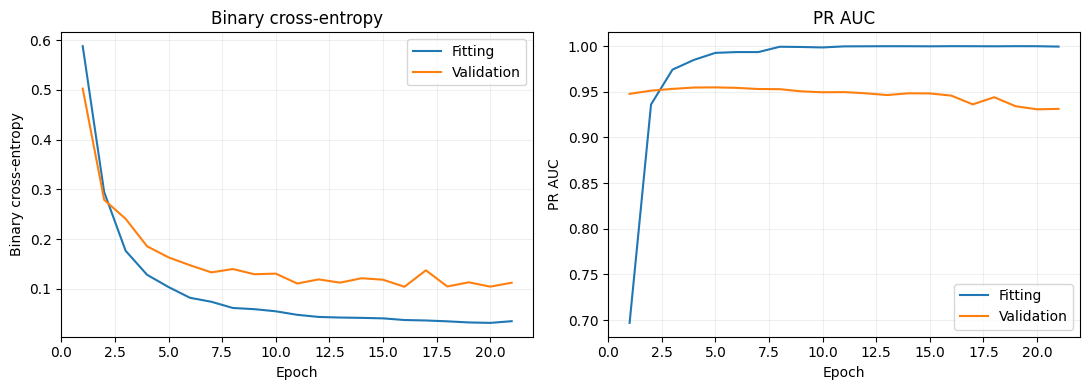

In [9]:
epoch_numbers = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ("loss", "pr_auc"), ("Binary cross-entropy", "PR AUC")):
    ax.plot(epoch_numbers, history.history[metric], label="Fitting")
    ax.plot(epoch_numbers, history.history["val_" + metric], label="Validation")
    ax.set(xlabel="Epoch", ylabel=title, title=title)
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / "learning_curves.png", dpi=120)
plt.show()
plt.close(fig)

## 5. Measure classification quality

Report accuracy and spam precision, recall and F1. Accuracy alone is insufficient
because most messages are ham. The confusion matrix uses rows for actual labels and
columns for predicted labels. Also report the distinct test texts absent from training.

In [10]:
def measure_predictions(targets, scores):
    targets = np.asarray(targets).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    if len(scores) != len(targets) or len(scores) == 0:
        raise ValueError("Targets and scores must be nonempty and have equal lengths")
    if not np.isin(targets, [0, 1]).all():
        raise ValueError("Targets must be zero or one")
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Scores must be finite values between zero and one")
    predicted = (scores >= 0.5).astype(int)
    return {"rows": len(targets), "accuracy": float(accuracy_score(targets, predicted)),
            "spam_precision": float(precision_score(targets, predicted, zero_division=0)),
            "spam_recall": float(recall_score(targets, predicted, zero_division=0)),
            "spam_f1": float(f1_score(targets, predicted, zero_division=0)),
            "confusion_matrix": confusion_matrix(targets, predicted, labels=[0, 1]).tolist()}

Provided test split: {
  "rows": 1392,
  "accuracy": 0.9791666666666666,
  "spam_precision": 0.9247311827956989,
  "spam_recall": 0.9197860962566845,
  "spam_f1": 0.9222520107238605,
  "confusion_matrix": [
    [
      1191,
      14
    ],
    [
      15,
      172
    ]
  ]
}
Unique test texts absent from training: {
  "rows": 1221,
  "accuracy": 0.9770679770679771,
  "spam_precision": 0.8978102189781022,
  "spam_recall": 0.8978102189781022,
  "spam_f1": 0.8978102189781022,
  "confusion_matrix": [
    [
      1070,
      14
    ],
    [
      14,
      123
    ]
  ]
}


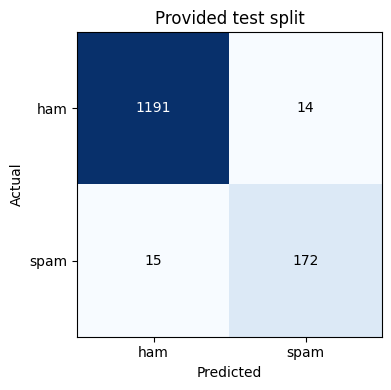

In [11]:
provided_scores = model(tf.constant(test_messages["message"].tolist()), training=False).numpy().reshape(-1)
novel_scores = model(tf.constant(novel_test["message"].tolist()), training=False).numpy().reshape(-1)
provided_metrics = measure_predictions(test_messages["target"], provided_scores)
novel_metrics = measure_predictions(novel_test["target"], novel_scores)
keras_metrics = model.evaluate(batches(test_messages), verbose=0, return_dict=True)
assert np.isclose(provided_metrics["accuracy"], keras_metrics["accuracy"], atol=1e-6)
print("Provided test split:", json.dumps(provided_metrics, indent=2))
print("Unique test texts absent from training:", json.dumps(novel_metrics, indent=2))

matrix = np.asarray(provided_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        ax.text(column, row, str(matrix[row, column]), ha="center", va="center",
                color="white" if matrix[row, column] > matrix.max() / 2 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["ham", "spam"], yticklabels=["ham", "spam"],
       xlabel="Predicted", ylabel="Actual", title="Provided test split")
fig.tight_layout()
fig.savefig(ARTIFACTS / "confusion_matrix.png", dpi=120)
plt.show()
plt.close(fig)

## 6. Implement the required function

Return a Python list containing the model's spam score and its label. The score is
a sigmoid model output, not a calibrated guarantee. A score of 0.5 or above maps to spam.
The same saved text preprocessing is used for training and inference.

In [12]:
def classify_message(pred_text, trained_model):
    if not isinstance(pred_text, str):
        raise TypeError("Message must be a string")
    if not pred_text.strip():
        raise ValueError("Message must not be empty")
    score = float(trained_model(tf.constant([pred_text]), training=False).numpy()[0, 0])
    return [score, "spam" if score >= 0.5 else "ham"]


def predict_message(pred_text):
    return classify_message(pred_text, model)

In [13]:
pred_text = "how are you doing today?"
prediction = predict_message(pred_text)
print(prediction)

[3.2930409361142665e-05, 'ham']


## 7. Run the unchanged freeCodeCamp check

The original test checks seven messages. Those examples are not used as a lookup table,
additional training examples or threshold-tuning data.

In [14]:
# Run this cell to test your function and model. Do not modify contents.
def test_predictions():
  test_messages = ["how are you doing today",
                   "sale today! to stop texts call 98912460324",
                   "i dont want to go. can we try it a different day? available sat",
                   "our new mobile video service is live. just install on your phone to start watching.",
                   "you have won £1000 cash! call to claim your prize.",
                   "i'll bring it tomorrow. don't forget the milk.",
                   "wow, is your arm alright. that happened to me one time too"
                  ]

  test_answers = ["ham", "spam", "ham", "spam", "spam", "ham", "ham"]
  passed = True

  for msg, ans in zip(test_messages, test_answers):
    prediction = predict_message(msg)
    if prediction[1] != ans:
      passed = False

  if passed:
    print("You passed the challenge. Great job!")
  else:
    print("You haven't passed yet. Keep trying.")

test_predictions()

You passed the challenge. Great job!


In [15]:
# Audit the examples defined inside the unchanged test without duplicating its text list.
import ast
import inspect
source_tree = ast.parse(inspect.getsource(test_predictions))
official_examples = {}
for node in ast.walk(source_tree):
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if isinstance(target, ast.Name) and target.id in {"test_messages", "test_answers"}:
                official_examples[target.id] = ast.literal_eval(node.value)
checks = [{"expected": expected, "spam_score": predict_message(text)[0],
           "predicted": predict_message(text)[1]}
          for text, expected in zip(official_examples["test_messages"], official_examples["test_answers"])]
passed_challenge = all(check["expected"] == check["predicted"] for check in checks)
assert len(checks) == 7 and passed_challenge, "Not all official example messages were classified correctly"
summary = {
    "tensorflow_version": tf.__version__, "seed": SEED, "dataset_hashes": DATA_HASHES,
    "provided_training_rows": len(raw_training), "deduplicated_training_rows": len(training_pool),
    "fitting_rows": len(fit_messages), "validation_rows": len(validation_messages),
    "provided_test_rows_seen_in_training_pool": int(overlap.sum()),
    "epochs_completed": len(history.history["loss"]), "selected_epoch": best_epoch,
    "decision_threshold": 0.5, "provided_test": provided_metrics,
    "novel_unique_test": novel_metrics, "provided_test_pr_auc": float(keras_metrics["pr_auc"]),
    "always_ham_baseline_accuracy": float((test_messages["target"] == 0).mean()),
    "official_examples_correct": sum(check["expected"] == check["predicted"] for check in checks),
    "official_examples_total": len(checks), "passed_challenge": passed_challenge,
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
(ARTIFACTS / "official_checks.json").write_text(json.dumps(checks, indent=2) + "\n", encoding="utf-8")
rows = pd.DataFrame({"row_index": test_messages.index, "actual_label": test_messages["label"],
                     "spam_score": provided_scores,
                     "predicted_label": np.where(provided_scores >= 0.5, "spam", "ham"),
                     "text_seen_in_training_pool": overlap})
rows.to_csv(ARTIFACTS / "test_predictions.csv", index=False)
pd.DataFrame(history.history).rename_axis("epoch").to_csv(ARTIFACTS / "training_history.csv")
print(f"Official examples correct: {sum(check['expected'] == check['predicted'] for check in checks)}/7")

Official examples correct: 7/7


## Use the classifier

Call `predict_message("your SMS text")` after running the notebook. To restore the
locally saved model, load `artifacts/sms_classifier.keras` with `keras.models.load_model`.
Its text preprocessing is included. Vocabulary learning and checkpoint selection do not
need to be repeated when restoring saved weights.

Results describe this English-language SMS dataset. Other languages, new spam campaigns
and unfamiliar writing styles may behave differently. The provided split's exact text
overlap is reported separately from the unique test texts absent from the training pool.